# ProteinStruct-ML — Exploratory Data Analysis (EDA)

 ## Objectives
- Investigate the distribution of RMSD.
- Explore the distributions of physicochemical descriptors F1–F9.
- Identify potential outliers and relationships between variables.
- Examine correlations between predictors and RMSD.
- Generate insights to guide machine learning model development.

## Inputs
- data/processed/casp_cleaned.csv

## Outputs
- Exploratory visualizations
- Statistical observations
- Insights for feature engineering and model selection



---

# Change working directory

* We are assuming you will store the notebooks in a subfolder, therefore when running the notebook in the editor, you will need to change the working directory

We need to change the working directory from its current folder to its parent folder
* We access the current directory with os.getcwd()

In [3]:
import os
from pathlib import Path

current_dir = Path.cwd()
print("Current directory:", current_dir)

Current directory: c:\Users\trasn\OneDrive\Dokumente\programing\ML fundamentals\Capstone\ProteinStruct-ML\jupyter_notebooks


We want to make the parent of the current directory the new current directory
* os.path.dirname() gets the parent directory
* os.chir() defines the new current directory

In [4]:
if Path.cwd().name == "jupyter_notebooks":
    os.chdir(Path.cwd().parent)

print("Working directory set to:", Path.cwd())

Working directory set to: c:\Users\trasn\OneDrive\Dokumente\programing\ML fundamentals\Capstone\ProteinStruct-ML


Confirm the new current directory

In [5]:
print("Confirmed project directory:", Path.cwd())

Confirmed project directory: c:\Users\trasn\OneDrive\Dokumente\programing\ML fundamentals\Capstone\ProteinStruct-ML


## Section 1 — Load Cleaned Dataset

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/processed/casp_cleaned.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (44019, 10)


,RMSD,F1,F2,F3,F4,F5,F6,F7,F8,F9
0,17.284,13558.30,4305.35,0.31754,162.1730,1.872791e+06,215.3590,4287.87,102,27.0302
1,6.021,6191.96,1623.16,0.26213,53.3894,8.034467e+05,87.2024,3328.91,39,38.5468
2,9.275,7725.98,1726.28,0.22343,67.2887,1.075648e+06,81.7913,2981.04,29,38.8119
3,15.851,8424.58,2368.25,0.28111,67.8325,1.210472e+06,109.4390,3248.22,70,39.0651
4,7.962,7460.84,1736.94,0.23280,52.4123,1.021020e+06,94.5234,2814.42,41,39.9147


## Section 2 — Target Variable Analysis

### Distribution of RMSD

The objective is to investigate the distribution of RMSD,
identify potential skewness, and understand the range of
structural deviations in the dataset.

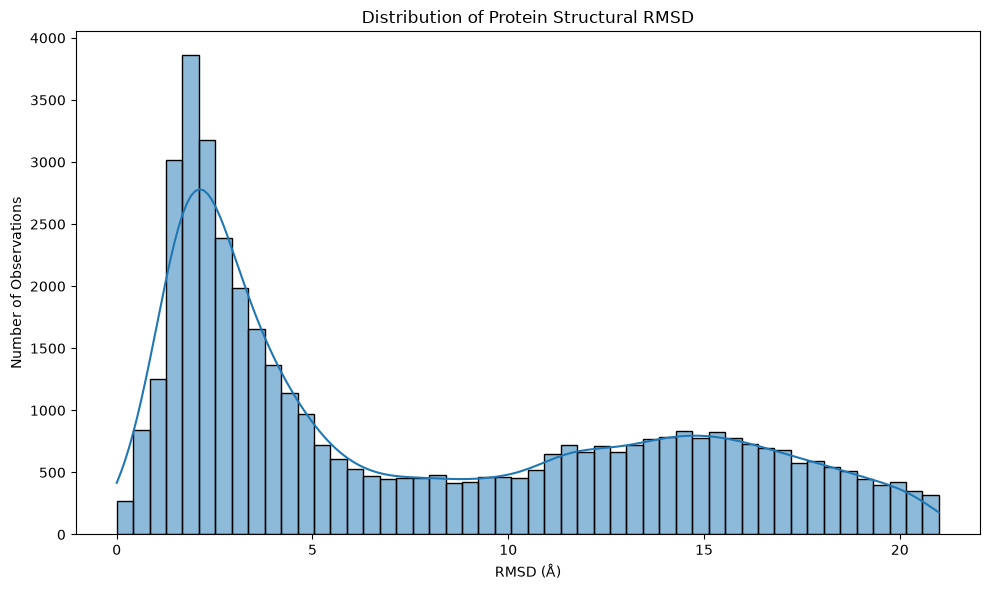

In [7]:
# Visualize the distribution of RMSD
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="RMSD",
    bins=50,
    kde=True
)

plt.title("Distribution of Protein Structural RMSD")
plt.xlabel("RMSD (Å)")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()

### RMSD Distribution — Findings

The RMSD histogram reveals a non-normal, apparently bimodal
distribution.

Two main concentrations of observations are visible:

- A prominent peak around 1.5–3 Å, representing protein models
  with relatively low structural deviation.
- A broader peak around 14–16 Å, representing models with
  substantially higher structural deviation.

The distribution contains fewer observations in the
intermediate RMSD range, approximately 7–10 Å.

This suggests that the dataset contains distinct regions
of structural deviation, although the underlying cause
cannot be established from the histogram alone.

**Implications for machine learning:**

- A single global error metric may conceal differences in
  predictive performance across RMSD ranges.
- Model evaluation should include MAE, RMSE, and R².
- Prediction errors may also be examined across low- and
  high-RMSD observations.

The target distribution will be preserved for regression.
No target transformation is applied at this stage.

In [8]:
# Calculate RMSD distribution statistics
print(f"Mean RMSD: {df['RMSD'].mean():.3f}")
print(f"Median RMSD: {df['RMSD'].median():.3f}")
print(f"Skewness: {df['RMSD'].skew():.3f}")
print(f"Kurtosis: {df['RMSD'].kurt():.3f}")

Mean RMSD: 7.796
Median RMSD: 5.087
Skewness: 0.553
Kurtosis: -1.162


### RMSD Distribution — Statistical Interpretation

The cleaned dataset has the following RMSD statistics:

- Mean: 7.796 Å
- Median: 5.087 Å
- Skewness: 0.553
- Excess kurtosis: -1.162

The positive skewness indicates moderate right-sided
asymmetry, consistent with the mean exceeding the median.

The negative excess kurtosis indicates a distribution with
lower kurtosis than a normal distribution.

Together with the histogram, these results indicate a
non-normal distribution with two apparent peaks.

**Machine Learning Implications**

The uneven target distribution may affect model performance
across different RMSD ranges.

In addition to overall MAE, RMSE, and R², prediction errors
will be examined across different RMSD intervals.

No target transformation will be applied at this stage.


## Section 2 — Target Variable Analysis

### Distribution of RMSD

The objective is to investigate the distribution of RMSD,
identify potential skewness, and understand the range of
structural deviations in the dataset.

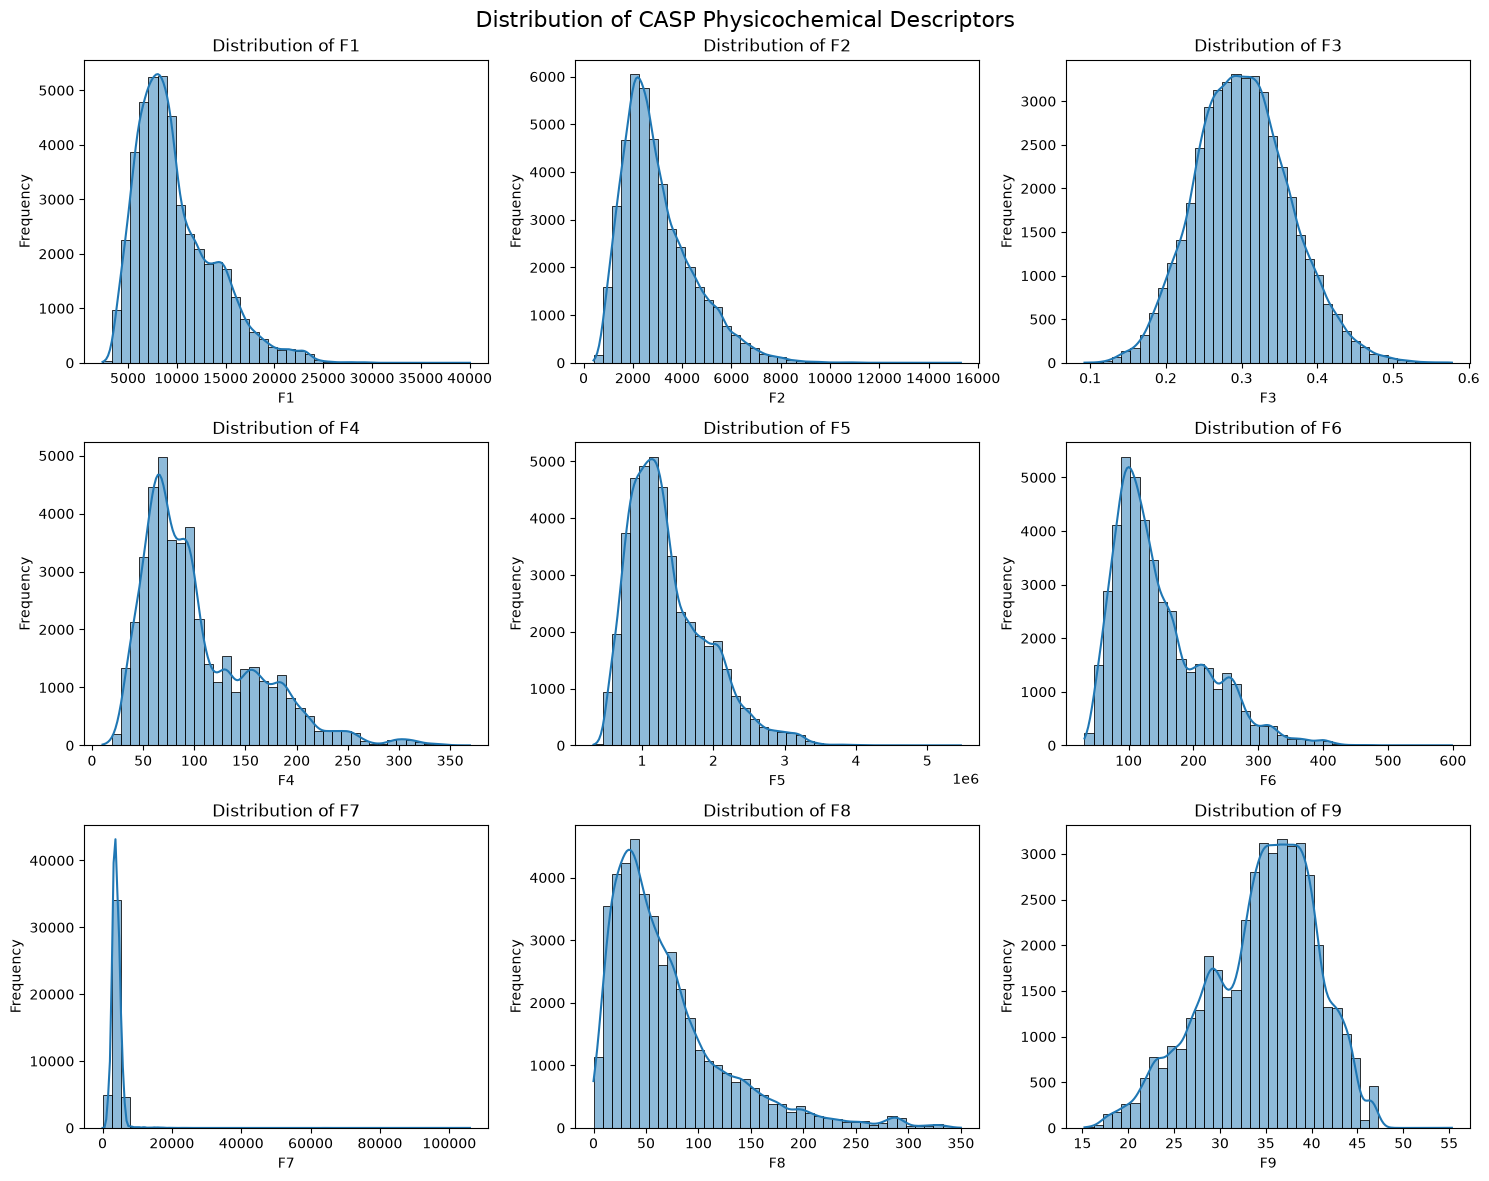

In [9]:
# Select the nine predictor variables
feature_columns = [f"F{i}" for i in range(1, 10)]

# Create histograms for all predictors
fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for ax, feature in zip(axes.flatten(), feature_columns):
    sns.histplot(
        data=df,
        x=feature,
        bins=40,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

plt.suptitle(
    "Distribution of CASP Physicochemical Descriptors",
    fontsize=16
)

plt.tight_layout()
plt.show()

### Physicochemical Descriptor Distributions — Findings

The nine predictor variables exhibit different distributional
characteristics.

**Right-skewed descriptors:**
F1, F2, F4, F5, F6, F7, and F8 show varying degrees of
positive skewness.

**Approximately symmetric descriptor:**
F3 exhibits a roughly bell-shaped distribution.

**Complex distribution:**
F9 shows an asymmetric distribution with multiple shoulders,
suggesting a more complex underlying pattern.

**Potential extreme values:**
F7 contains particularly large upper-tail observations,
with a maximum exceeding 100,000.

**Machine Learning Implications:**

- Predictor variables have substantially different scales.
- Feature scaling may benefit scale-sensitive models.
- Extreme values may affect certain regression algorithms.
- Tree-based models are generally less sensitive to feature
  scaling.
- No outliers will be removed without further investigation.

Feature transformations, if required, will be implemented
within the machine learning workflow to avoid data leakage.

### Investigation of Extreme Values in F7

In [10]:
# Examine extreme values in F7
print("F7 percentiles:")
display(df["F7"].quantile([0.50, 0.90, 0.95, 0.99, 0.999, 1.00]))

print("\nObservations with F7 > 10000:",
      (df["F7"] > 10000).sum())

print("Observations with F7 > 20000:",
      (df["F7"] > 20000).sum())

F7 percentiles:


0.500      3840.54000
0.900      5371.41600
0.950      5759.70500
0.990      7244.05080
0.999     19873.50392
1.000    105948.17000
Name: F7, dtype: float64


Observations with F7 > 10000: 267
Observations with F7 > 20000: 43


### F7 Extreme Value Investigation — Findings

F7 exhibits a strongly right-skewed distribution with a
small number of exceptionally high values.

Key findings:
- Median: 3,840.54
- 99th percentile: 7,244.05
- 99.9th percentile: 19,873.50
- Maximum: 105,948.17
- 267 observations (0.61%) exceed 10,000.
- 43 observations (0.10%) exceed 20,000.

The maximum is approximately 27.6 times the median,
indicating an extreme upper tail.

These observations are not automatically considered errors.
They will be retained because their scientific validity
cannot be determined from the available data alone.

Potential transformations or robust preprocessing methods
may be evaluated during model development.


## Section 4 — Correlation Analysis

### Pearson Correlation Matrix

The objective is to investigate linear relationships between
RMSD and the nine physicochemical descriptors (F1–F9).

We will also examine correlations among predictors to identify
potential multicollinearity that could influence linear regression.

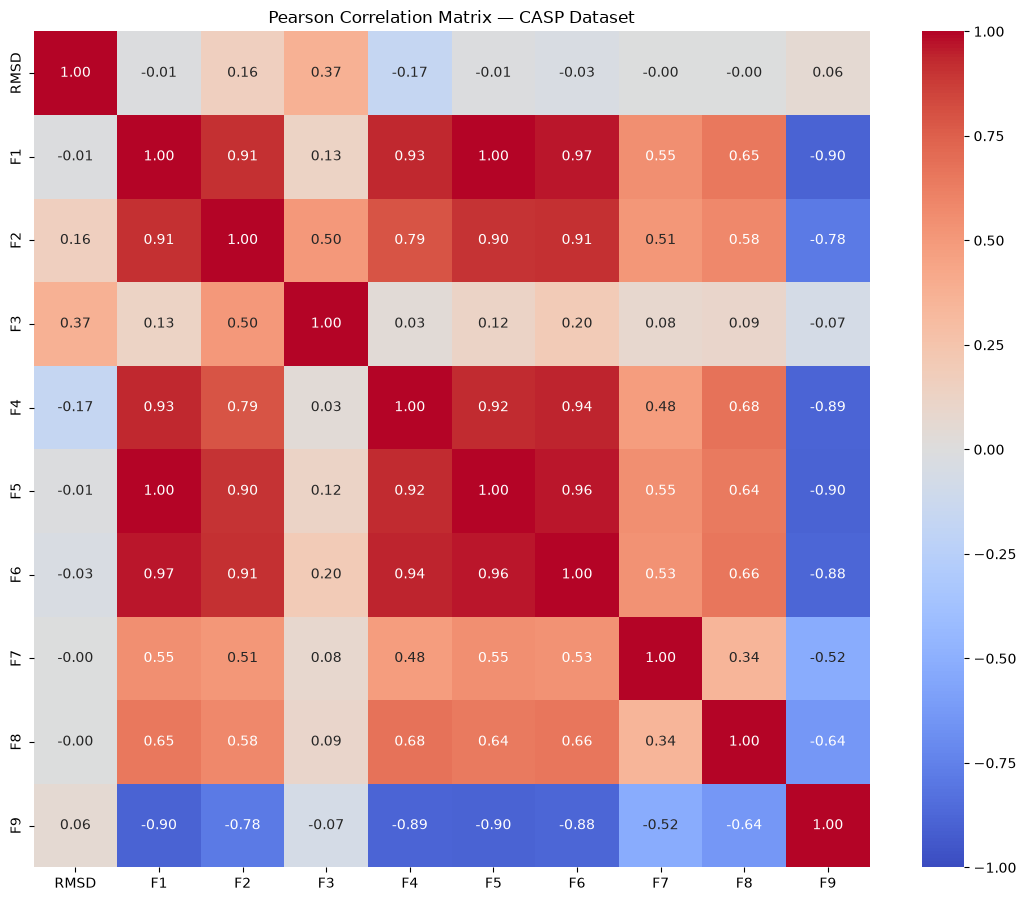

In [11]:
# Calculate the Pearson correlation matrix
corr_matrix = df.corr(method="pearson")

# Create the correlation heatmap
plt.figure(figsize=(11, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Pearson Correlation Matrix — CASP Dataset")
plt.tight_layout()
plt.show()

### Pearson Correlation Analysis — Findings

The correlation matrix reveals two important characteristics
of the CASP dataset.

**1. Relationships with RMSD**

F3 exhibits the strongest positive linear association with
RMSD (r = 0.37).

F4 (r = -0.17) and F2 (r = 0.16) show weaker linear
relationships.

Most remaining descriptors have negligible individual
Pearson correlations with RMSD.

This does not imply that these features lack predictive
value, because Pearson correlation captures only linear
relationships.

**2. Multicollinearity among predictors**

Several physicochemical descriptors are strongly correlated:

- F1 and F5: r approximately 1.00
- F1 and F6: r = 0.97
- F5 and F6: r = 0.96
- F4 and F6: r = 0.94
- F1 and F9: r = -0.90

These relationships suggest substantial multicollinearity.

**Machine Learning Implications**

- Linear regression will provide an interpretable benchmark,
  but correlated predictors may complicate coefficient
  interpretation.
- Nonlinear models such as Random Forest and
  HistGradientBoosting will be evaluated.
- Feature importance and predictive performance will be
  assessed before considering feature removal.
- No predictors will be removed solely based on the
  correlation matrix.


In [12]:
# Rank predictor correlations with RMSD
rmsd_correlations = (
    df.corr(method="pearson")["RMSD"]
    .drop("RMSD")
    .sort_values(key=abs, ascending=False)
)

print("Predictor correlations with RMSD:")
display(rmsd_correlations)

Predictor correlations with RMSD:


F3    0.373389
F4   -0.169258
F2    0.158351
F9    0.061939
F6   -0.034420
F1   -0.013087
F5   -0.011956
F7   -0.003116
F8   -0.000032
Name: RMSD, dtype: float64

### Correlation Analysis — Conclusions

F3 shows the strongest individual linear association with RMSD
(r = 0.3734), followed by F4 (r = -0.1693) and F2 (r = 0.1584).

The remaining predictors exhibit weak or negligible linear
correlations with the target.

However, low Pearson correlation does not exclude nonlinear
predictive relationships or interactions between variables.

Strong correlations among several predictors also indicate
substantial multicollinearity.

These findings motivate comparing linear regression with
nonlinear ensemble models.

All nine predictors will initially be retained for modeling.


## Section 2 — Target Variable Analysis

### Distribution of RMSD

The objective is to investigate the distribution of RMSD,
identify potential skewness, and understand the range of
structural deviations in the dataset.

---

# Section 2

Section 2 content

---

NOTE

* You may add as many sections as you want, as long as it supports your project workflow.
* All notebook's cells should be run top-down (you can't create a dynamic wherein a given point you need to go back to a previous cell to execute some task, like go back to a previous cell and refresh a variable content)

---

# Push files to Repo

* In cases where you don't need to push files to Repo, you may replace this section with "Conclusions and Next Steps" and state your conclusions and next steps.

In [ ]:
import os
try:
  # create your folder here
  # os.makedirs(name='')
except Exception as e:
  print(e)
